# Settings

In [1]:
run_beamforming = True
beamform_interpolated = False

#saved names
beamformed_image_name = "000_test1_angle0"

# Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit
import json
from scipy import signal

# Import parameters

In [3]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

def calculate_variables(params):
    array_length = params["array"]["length"] #transducer array length
    frequency = params["wave"]["frequency"] #hz
    c = params["wave"]["c"] #speed of sound in m/s
    sampling_rate = params["wave"]["sampling_rate"] #1/s = 16 * frequency
    total_depth = params["simulation"]["total_depth"] #total depth in m
    pitch = params["array"]["pitch"] #pitch in m
    interpolation_factor = params["simulation"]["interpolation_factor"] #interpolation factor   
    
    step_size = 1 / sampling_rate #cuz frequency = 1 / T 
    samples = int(sampling_rate * (total_depth / c)) #sampling rate 1/s * total depth m / (m/s) = samples - samples needed to cover the total depth
    upsampled_samples = samples + (interpolation_factor - 1) * (samples - 1)
    
    pos = np.linspace(start=0, stop=array_length, num=array_length, dtype=int) #array position sampling
    time = np.linspace(start=0, stop=step_size * samples, num=samples) #time sampling
    
    params["simulation"]["step_size"] = step_size #step size in s
    params["simulation"]["samples"] = samples
    params["simulation"]["upsampled_samples"] = upsampled_samples
    params["simulation"]["upsampled_sampling_rate"] = sampling_rate * interpolation_factor
    
    #more info
    params["simulation"]["maximal_acquisition_depth"] = c * (step_size * samples) / 2 #maximal acquisition depth in m
    params["simulation"]["lateral_step"] = (array_length * pitch) * (1 / params['simulation']['lateral_resolution'])

    
    print("Aperture: ", params["array"]["aperture"])
    print("Samples: ", samples)
    print("Upsampled samples: ", upsampled_samples)
    print("Step size: ", step_size, "s")
    print("Maximal acquisition depth:", params["simulation"]["maximal_acquisition_depth"], "m")
    print("Lateral step: ", params["simulation"]["lateral_step"], "m")
    
    return params, pos, time

In [4]:
parameters = load_parameters("./parameters.json")
params, pos, time = calculate_variables(parameters)

Aperture:  0.8
Samples:  800
Upsampled samples:  3197
Step size:  1.6666666666666667e-08 s
Maximal acquisition depth: 0.01 m
Lateral step:  2.5e-05 m


## Objects

In [5]:
class Objects:
    def __init__(self, depth, position, array_length, samples, upsampled_samples, angles_len):
        self.depth = depth
        self.position = position
        self.delays = np.zeros(shape = (array_length, angles_len))
        self.rf_matrix = np.zeros(shape = (samples, array_length, angles_len))
        self.rf_matrix_upsampled = np.zeros(shape = (upsampled_samples, array_length, angles_len))
        self.effective_array_length = 0
        self.effective_angle = 0

In [6]:
objects = []

for reflector in params["objects"]:
    objects.append(
        Objects(
            reflector["depth"], 
            reflector["position"], 
            params["array"]["length"], 
            params["simulation"]["samples"], 
            params["simulation"]["upsampled_samples"],
            len(params["wave"]["angles"])
            )    
        )

# Signals

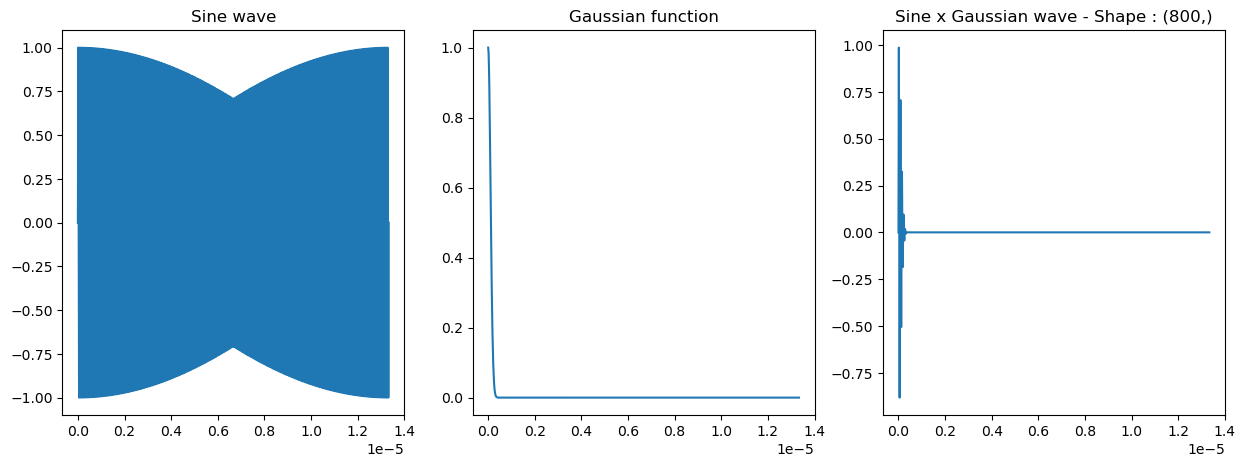

In [7]:
gaussian_std = 0.0000001

def sine_wave(frequency, timestep):
    return np.sin(2*np.pi*frequency*timestep)

def gaussian_function(timestep, std):
    return np.exp(-timestep**2 / (2 * std**2))

def generate_wave(frequency, timestep, std):
    return sine_wave(frequency, timestep) * gaussian_function(timestep, std)

fig, ax = plt.subplots(1,3, figsize=(15,5))

wave1, wave2, wave3 = sine_wave(params['wave']['frequency'], time), gaussian_function(time, gaussian_std), generate_wave(params['wave']['frequency'], time, gaussian_std)
ax[0].plot(time, wave1)
ax[0].set_title("Sine wave")

ax[1].plot(time, wave2)
ax[1].set_title("Gaussian function")

ax[2].plot(time, wave3)
ax[2].set_title(f"Sine x Gaussian wave - Shape : {wave3.shape}")
plt.show()

# Interpolation

In [8]:
def zero_stuffing(rf_matrices_summed, interpolation_factor, upsampled_samples):
    interpolation_factor = interpolation_factor - 1
    new_matrices_summed = np.zeros((upsampled_samples, rf_matrices_summed.shape[1], rf_matrices_summed.shape[2]))
    
    for i in range(rf_matrices_summed.shape[2]): #for each angle
        for j in range(rf_matrices_summed.shape[1]): #for each transducer
            for k in range(rf_matrices_summed.shape[0]): #for each sample
                idx_new = k + (interpolation_factor * k)
                new_matrices_summed[idx_new, j, i] = rf_matrices_summed[k, j, i]

    return new_matrices_summed

In [9]:
def get_filtered_matrices(zero_stuffed_rf_matrices_summed, frequency, sampling_frequency):
    filtered_rf_matrices_summed = np.zeros((zero_stuffed_rf_matrices_summed.shape[0], zero_stuffed_rf_matrices_summed.shape[1], zero_stuffed_rf_matrices_summed.shape[2]))

    new_samples = zero_stuffed_rf_matrices_summed.shape[0]
    cutoff_freq = 0.50 * frequency #use Nyquist frequency as cutoff frequency
    
    filtering_function = signal.firwin(new_samples, cutoff_freq, fs=sampling_frequency)

    for i in range(0, zero_stuffed_rf_matrices_summed.shape[2]): #for each angle
        for j in range(0, zero_stuffed_rf_matrices_summed.shape[1]): #for each transducer
            filtered_rf_matrices_summed[:,j,i] = np.convolve(zero_stuffed_rf_matrices_summed[:,j,i], filtering_function, mode='same')

    return filtered_rf_matrices_summed

# Delays

In [10]:
def delay_function(object_depth, object_position, speed_sound, array_position, pitch, angle):
    return ((object_depth * np.cos(angle * np.pi/180) + object_position * np.sin(angle * np.pi/180)) / speed_sound)  + (np.sqrt(object_depth**2 + (array_position * pitch - object_position)**2) / speed_sound)

In [11]:
def get_delays(objects, c, pitch, array_length, angles, destination="./data/csv/delays/"):
    for i in range(0, len(angles)):
        for j in range(0, len(objects)):
            for k in range(0, array_length):
                 objects[j].delays[k, i] = delay_function(object_depth=objects[j].depth, object_position=objects[j].position, speed_sound=c, array_position=k, pitch=pitch, angle=angles[i])

    for i, reflector in enumerate(objects):
        np.save(f"{destination}delay_matrix_object{i+1}", reflector.delays)

get_delays(objects, params['wave']['c'], params['array']['pitch'], params['array']['length'], params["wave"]["angles"])

## Showing delay results

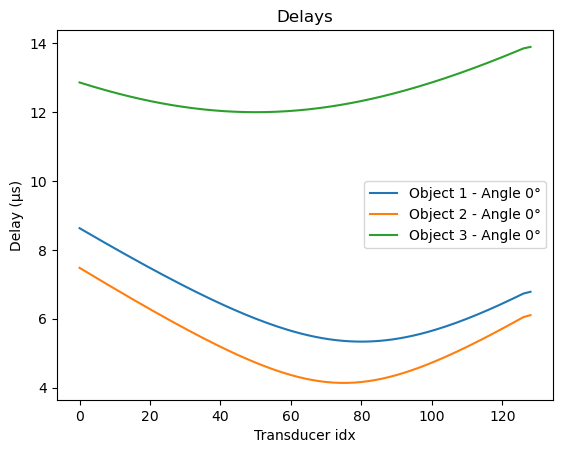

In [12]:
plt.figure()    
for i in range (0, len(params["wave"]["angles"])):
    for j in range(0, len(objects)):
        plt.plot(pos, objects[j].delays[:,i]*1e6, label = f"Object {j+1} - Angle {params['wave']['angles'][i]}°")
plt.title("Delays")
plt.xlabel("Transducer idx")
plt.ylabel("Delay (µs)")
plt.legend()
plt.show()

## Find object effective aperture 

In [13]:
def find_object_effective_aperture(objects, aperture):
    for i in range(0, len(objects)):
        objects[i].effective_array_length =  objects[i].depth / aperture

find_object_effective_aperture(objects, params["array"]["aperture"])

## Wave delays

In [14]:
def is_in_transducer_range(current_object : Objects, current_transducer, pitch):
    if current_transducer * pitch <= current_object.position - current_object.effective_array_length / 2 or current_transducer * pitch >= current_object.position + current_object.effective_array_length / 2:
        return 0
    else:
        return np.cos(np.abs(current_object.position - current_transducer * pitch) / current_object.effective_array_length) ** 18

In [15]:
def get_rf_matrices(objects : Objects, frequency, time, array_length, pitch, gaussian_std, samples, upsampled_samples, interpolation_factor, sampling_rate, angles = [0], destination="./data/csv/rf_data/"):
    rf_matrices_summed = np.zeros((samples, array_length, len(angles)))
    rf_matrices_upsampled_summed = np.zeros((upsampled_samples, array_length, len(angles)))

    for i in range(0, len(angles)):
        for j in range(0, len(objects)):
            for k in range(array_length):
                #for each transducer, generate the wave with the corresponding delay
                objects[j].rf_matrix[:,k,i] += generate_wave(frequency, time - objects[j].delays[k,i], gaussian_std) * is_in_transducer_range(objects[j], k, pitch)
            
            rf_matrices_summed[:,:,i] += objects[j].rf_matrix[:,:,i] 

    for i, reflector in enumerate(objects):
        np.save(f"{destination}rf_matrix_object{i+1}", reflector.rf_matrix)

        temp_zero_stuffed = zero_stuffing(reflector.rf_matrix, interpolation_factor, upsampled_samples)
        temp_upsampled = get_filtered_matrices(temp_zero_stuffed, frequency, sampling_rate)

        objects[i].rf_matrix_upsampled = temp_upsampled
        rf_matrices_upsampled_summed += temp_upsampled
        
        np.save(f"{destination}rf_matrix_upsampled_object{i+1}", temp_upsampled)

    np.save(f"{destination}rf_matrix_upsampled_summed", rf_matrices_upsampled_summed)
    np.save(f"{destination}rf_matrix_summed", rf_matrices_summed)
    return rf_matrices_summed, rf_matrices_upsampled_summed

In [16]:
rf_matrices_summed, rf_matrices_upsampled_summed = get_rf_matrices(objects, 
                                                                    params['wave']['frequency'],
                                                                    time,  
                                                                    params['array']['length'],  
                                                                    params["array"]["pitch"],  
                                                                    gaussian_std,  
                                                                    params["simulation"]["samples"],  
                                                                    params["simulation"]["upsampled_samples"],
                                                                    params["simulation"]["interpolation_factor"],
                                                                    params["wave"]["sampling_rate"],
                                                                    params["wave"]["angles"]
                                                                    )

## Showing wave results

In [17]:
def plot_rf_matrices_heatmaps(rf_matrices_summed, angles = [0]):
    n_matrices = rf_matrices_summed.shape[2]
    n_cols = min(3, n_matrices)
    n_rows = (n_matrices + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*5, n_rows*4))
    
    if n_matrices > 1 and n_rows > 1:
        axes = axes.flatten()
    elif n_matrices > 1:
        #if single row but multiple columns
        axes = axes
    else:
        #if just one plot - otherwise obj is not subscriptable
        axes = [axes]
    
    for i in range(n_matrices):
        if i < len(axes):
            im = axes[i].imshow(np.abs(rf_matrices_summed[:,:,i]), aspect='auto', cmap='hot')
            axes[i].set_title(f'RF Matrix at Angle {angles[i]}°')
            axes[i].set_xlabel('Transducer idx')
            axes[i].set_ylabel('Sample idx')
            fig.colorbar(im, ax=axes[i], label='Amplitude')

    for i in range(n_matrices, len(axes)):
        fig.delaxes(axes[i]) #remove empty plots
    
    plt.tight_layout()
    plt.savefig('./data/images/rf_matrices.png')
    plt.show()

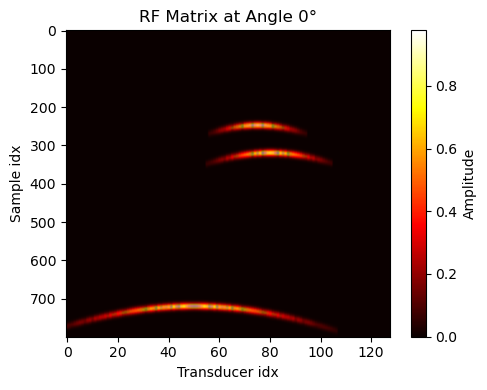

In [18]:
plot_rf_matrices_heatmaps(rf_matrices_summed, params["wave"]["angles"])

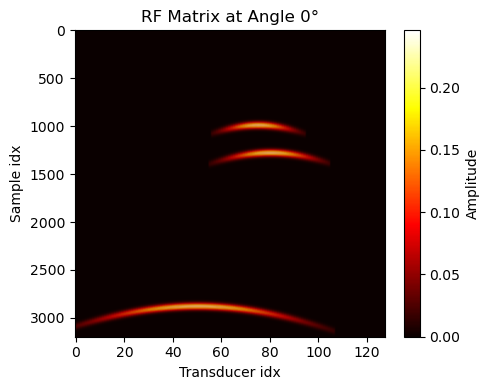

In [19]:
plot_rf_matrices_heatmaps(rf_matrices_upsampled_summed, params["wave"]["angles"])

# Beamforming

In [20]:
def save_beamformed_data(bf_matrix, filename, destination="./data/csv/beamformed/"):
    np.save(f"{destination}{filename}", bf_matrix)
    print("Beamformed data saved")

In [21]:
@njit(parallel=True)
def beamforming_opt(rf_summed_matrices, lateral_resolution, samples, total_depth, pitch, c, array_length, sampling_rate, angles = [0]):
    bf_matrices = np.zeros((samples, lateral_resolution, len(angles)))
    depth_step = (total_depth / 2) / samples #total depth in m / number of samples = depth per sample

    for i in range(0, len(angles)): #for each angle

        for j in range(0, lateral_resolution): #for each lateral res sample

            for k in range(0, samples): #for vertical res sample

                depth = depth_step*k
                position = (pitch * array_length) * (j / lateral_resolution) #pitch isnt the same as the distance between transducers
                # we normalize the index to the total array length

                for l in range(0, array_length): #for each transducer

                    delay = ((depth * np.cos(angles[i] * np.pi/180) + position * np.sin(angles[i] * np.pi/180)) / c)  + (np.sqrt(depth**2 + (l * pitch - position)**2) / c)
                    delay_idx = int(delay * sampling_rate) #delay in s * sampling rate in 1/s = delay in samples (number of samples to reach delay)

                    if delay_idx < samples:
                        bf_matrices[k,j,i] += rf_summed_matrices[delay_idx, l, i] #we take sample in calculated rf_matrix (faster than recalculating)
        
        print("Beamforming done for angle", angles[i], '°')
    return bf_matrices

In [22]:
if run_beamforming:
    bf_matrices = beamforming_opt(
        rf_matrices_upsampled_summed if beamform_interpolated else rf_matrices_summed, 
        params["simulation"]["lateral_resolution"], 
        params["simulation"]["upsampled_samples"] if beamform_interpolated else params["simulation"]["samples"], 
        params["simulation"]["total_depth"], 
        params["array"]["pitch"], 
        params["wave"]["c"], 
        params["array"]["length"], 
        params["simulation"]["upsampled_sampling_rate"] if beamform_interpolated else params["wave"]["sampling_rate"], 
        angles=params["wave"]["angles"]
    )

    bf_matrix_summed = np.sum(bf_matrices, axis=2)

    save_beamformed_data(bf_matrix_summed, beamformed_image_name)

Beamforming done for angle 0 °
Beamformed data saved


## Visualize beamformed image

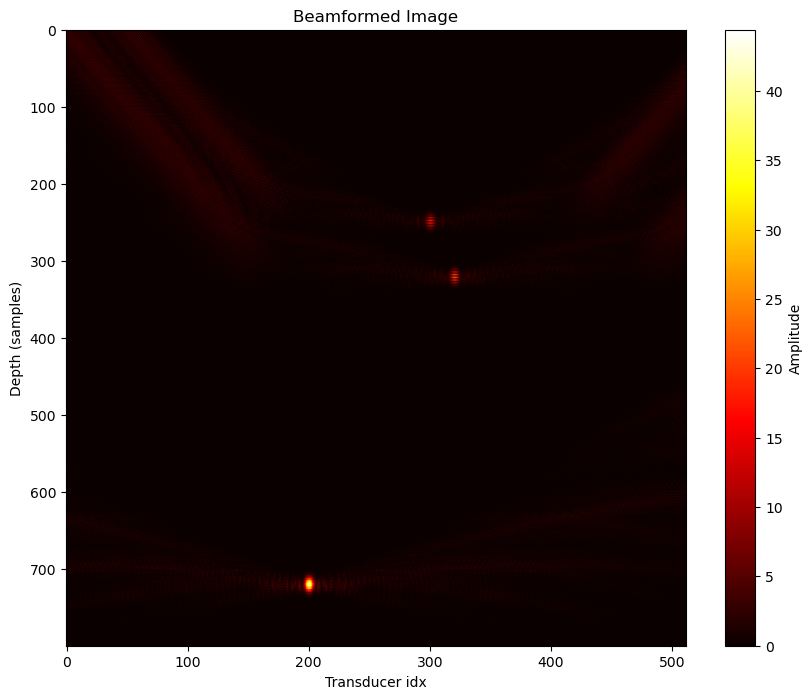

In [23]:
if run_beamforming:
    plt.figure(figsize=(10, 8))
    plt.imshow(np.abs(bf_matrix_summed), cmap='hot', aspect='auto')
    plt.title("Beamformed Image")
    plt.xlabel("Transducer idx")
    plt.ylabel("Depth (samples)")
    plt.colorbar(label="Amplitude")
    plt.savefig("./data/images/bf_image_angles.png")
    plt.show()

# Explanation

## The Core Concept
The key insight is that if there was a **reflector at the pixel location:**
- Each transducer would have received a reflection at a specific delay time
- By looking up what was actually measured at those specific delay times
- And adding them together
- We get constructive interference where actual reflectors exist

This is the fundamental principle behind delay-and-sum beamforming.
When we align and sum the signals properly, reflections from real objects add constructively, while noise tends to cancel out.

Example Scenario:

Imagine a reflector at depth 5mm:

- For a centered transducer, the echo might arrive at 6.67 μs (5mm ÷ 1500 m/s × 2)
- For an off-center transducer, it would take slightly longer due to the diagonal path
- When we sum the signals at their correct delay times, the reflector "appears" in our image
- This technique essentially transforms time-domain signals into a spatial image, revealing the locations of reflectors in your imaging field